In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




In [4]:
df = pd.read_csv("Sample - Superstore.csv", encoding="latin-1")
df.head()
df.info()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [12]:
#cleaning data
#1. turn the text dates into real dates
df["Order Date"] = pd.to_datetime(df["Order Date"])
print(df["Order Date"].min(), "to", df["Order Date"].max())

2014-01-03 00:00:00 to 2017-12-30 00:00:00


In [8]:
#2. find ands remove duplicate ,ignoring Row ID
columns_to_check = df.columns.drop("Row ID")
print("Duplicates:", df.duplicated(subset=columns_to_check).sum())
df = df.drop_duplicates(subset=columns_to_check)
print("Rows now:", len(df))


Duplicates: 1
Rows now: 9993


In [14]:
# 3. Add time columns for later grouping
df["Year"] = df["Order Date"].dt.year
df["Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

In [15]:
print(df.shape)
df[["Order Date", "Year", "Quarter", "Month"]].head()

(9993, 25)


,Order Date,Year,Quarter,Month
0,2016-11-08,2016,2016Q4,2016-11
1,2016-11-08,2016,2016Q4,2016-11
2,2016-06-12,2016,2016Q2,2016-06
3,2015-10-11,2015,2015Q4,2015-10
4,2015-10-11,2015,2015Q4,2015-10


In [16]:
# Remove the extra column from the earlier typo
df = df.drop(columns="Order Dates", errors="ignore")

# Core business metrics
total_revenue = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_revenue * 100
total_orders = df["Order ID"].nunique()
average_order_value = total_revenue / total_orders
total_units = df["Quantity"].sum()

print(f"Columns now: {df.shape[1]}")
print(f"Total revenue: ${total_revenue:,.2f}")
print(f"Total profit: ${total_profit:,.2f}")
print(f"Profit margin: {profit_margin:.2f}%")
print(f"Total orders: {total_orders:,}")
print(f"Average order value: ${average_order_value:,.2f}")
print(f"Units sold: {total_units:,}")

Columns now: 24
Total revenue: $2,296,919.49
Total profit: $286,409.08
Profit margin: 12.47%
Total orders: 5,009
Average order value: $458.56
Units sold: 37,871


In [17]:
yearly_sales = df.groupby("Year")["Sales"].sum()
quarterly_sales = df.groupby("Quarter")["Sales"].sum()
monthly_sales = df.groupby("Month")["Sales"].sum()

print(yearly_sales.round(0))
print(quarterly_sales.round(0))
print("Totals match:", round(monthly_sales.sum(), 2) == round(total_revenue, 2))

Year
2014    483966.0
2015    470533.0
2016    609206.0
2017    733215.0
Name: Sales, dtype: float64
Quarter
2014Q1     74448.0
2014Q2     86257.0
2014Q3    143633.0
2014Q4    179628.0
2015Q1     68852.0
2015Q2     89124.0
2015Q3    130260.0
2015Q4    182297.0
2016Q1     93237.0
2016Q2    136082.0
2016Q3    143787.0
2016Q4    236099.0
2017Q1    123145.0
2017Q2    133764.0
2017Q3    196252.0
2017Q4    280054.0
Name: Sales, dtype: float64
Totals match: True


In [18]:
seasonal_sales = df.groupby(df["Order Date"].dt.month)["Sales"].sum() / df["Year"].nunique()
seasonal_sales.round(0)

Order Date
1     23731.0
2     14938.0
3     51251.0
4     34370.0
5     38757.0
6     38180.0
7     36810.0
8     39761.0
9     76912.0
10    50081.0
11    88115.0
12    81323.0
Name: Sales, dtype: float64

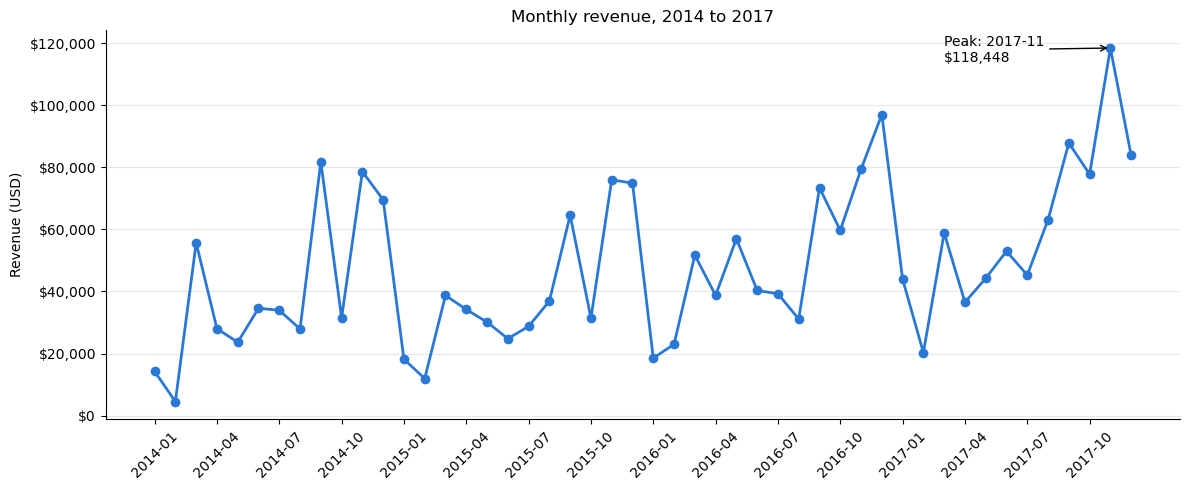

In [19]:
import os
import matplotlib.pyplot as plt

peak_month = monthly_sales.idxmax()
peak_value = monthly_sales.max()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_sales.index, monthly_sales.values, marker="o", color="#2a78d6", linewidth=2)

ax.annotate(
    f"Peak: {peak_month}\n${peak_value:,.0f}",
    xy=(peak_month, peak_value),
    xytext=(-120, -10),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
)

ax.set_title("Monthly revenue, 2014 to 2017")
ax.set_ylabel("Revenue (USD)")
ax.set_xticks(monthly_sales.index[::3])
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

os.makedirs("charts", exist_ok=True)
plt.tight_layout()
plt.savefig("charts/monthly_revenue.png", dpi=300)
plt.show()

In [20]:
#finding best and worst products
category_summary = df.groupby("Category").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Units=("Quantity", "sum"),
)
category_summary["Margin %"] = category_summary["Profit"] / category_summary["Revenue"] * 100
category_summary = category_summary.sort_values("Revenue", ascending=False).round(2)

print("Totals match:", round(category_summary["Revenue"].sum(), 0) == round(total_revenue, 0))
category_summary

Totals match: True


,Revenue,Profit,Units,Margin %
Category,,,,
Technology,836154.03,145454.95,6939,17.40
Furniture,741718.42,18463.33,8026,2.49
Office Supplies,719047.03,122490.80,22906,17.04


In [21]:
subcategory_summary = df.groupby("Sub-Category").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Units=("Quantity", "sum"),
)
subcategory_summary["Margin %"] = subcategory_summary["Profit"] / subcategory_summary["Revenue"] * 100
subcategory_summary = subcategory_summary.sort_values("Profit", ascending=False).round(2)

print("Totals match:", round(subcategory_summary["Revenue"].sum(), 0) == round(total_revenue, 0))
subcategory_summary

Totals match: True


,Revenue,Profit,Units,Margin %
Sub-Category,,,,
Copiers,149528.03,55617.82,234,37.20
Phones,330007.05,44515.73,3289,13.49
Accessories,167380.32,41936.64,2976,25.05
Paper,78479.21,34053.57,5178,43.39
Binders,203412.73,30221.76,5974,14.86
Chairs,328167.73,26602.23,2354,8.11
Storage,223843.61,21278.83,3158,9.51
Appliances,107532.16,18138.01,1729,16.87
Furnishings,91705.16,13059.14,3563,14.24


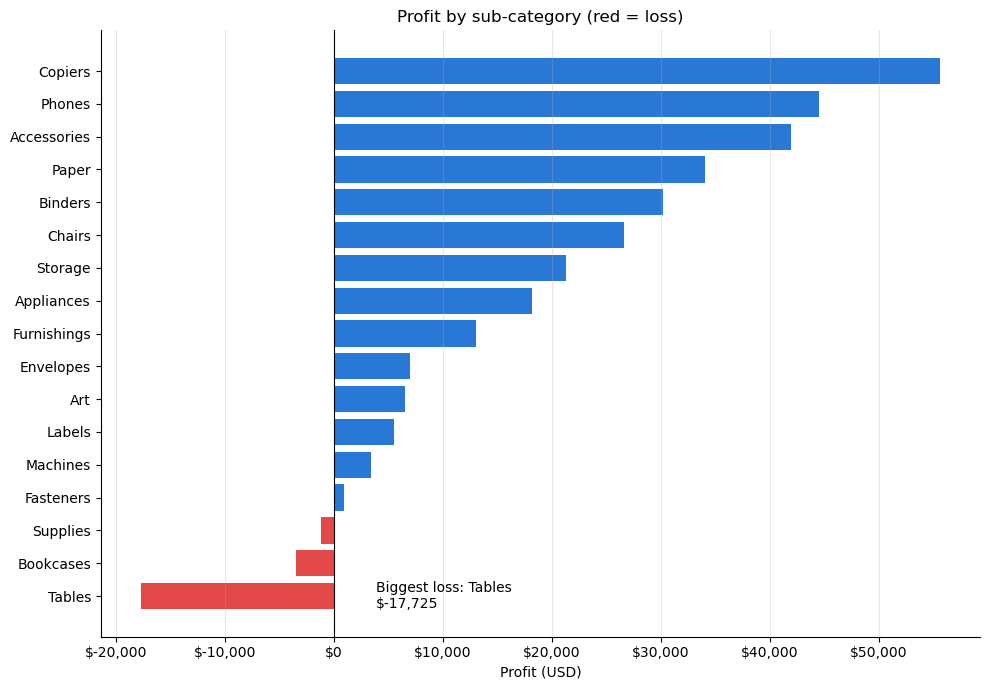

In [22]:
chart_data = subcategory_summary.sort_values("Profit")
colors = ["#e34948" if value < 0 else "#2a78d6" for value in chart_data["Profit"]]

worst_name = chart_data.index[0]
worst_value = chart_data["Profit"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(chart_data.index, chart_data["Profit"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)

ax.annotate(
    f"Biggest loss: {worst_name}\n${worst_value:,.0f}",
    xy=(0, worst_name),
    xytext=(30, 0),
    textcoords="offset points",
    va="center",
)

ax.set_title("Profit by sub-category (red = loss)")
ax.set_xlabel("Profit (USD)")
ax.xaxis.set_major_formatter("${x:,.0f}")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/subcategory_profit.png", dpi=300)
plt.show()

In [23]:
region_summary = df.groupby("Region").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
)
region_summary["Margin %"] = region_summary["Profit"] / region_summary["Revenue"] * 100
region_summary = region_summary.sort_values("Revenue", ascending=False).round(2)

print("Totals match:", round(region_summary["Revenue"].sum(), 0) == round(total_revenue, 0))
region_summary

Totals match: True


,Revenue,Profit,Orders,Margin %
Region,,,,
West,725457.82,108418.45,1611,14.94
East,678499.87,91534.84,1401,13.49
Central,501239.89,39706.36,1175,7.92
South,391721.90,46749.43,822,11.93


In [24]:
state_summary = df.groupby("State").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
state_summary["Margin %"] = state_summary["Profit"] / state_summary["Revenue"] * 100
state_summary = state_summary.round(2)

losing_states = state_summary[state_summary["Profit"] < 0].sort_values("Profit")
print("States losing money:", len(losing_states))
losing_states.head(5)

States losing money: 10


,Revenue,Profit,Margin %
State,,,
Texas,170188.05,-25729.36,-15.12
Ohio,77976.76,-16959.32,-21.75
Pennsylvania,116511.91,-15559.96,-13.35
Illinois,80166.10,-12607.89,-15.73
North Carolina,55603.16,-7490.91,-13.47


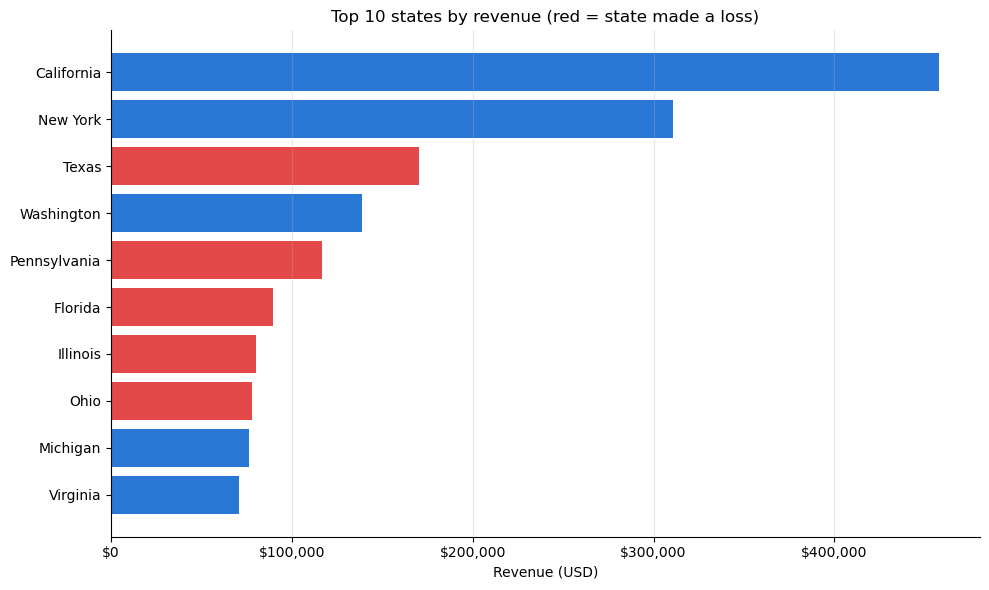

In [25]:
top_states = state_summary.sort_values("Revenue", ascending=False).head(10).sort_values("Revenue")
colors = ["#e34948" if value < 0 else "#2a78d6" for value in top_states["Profit"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_states.index, top_states["Revenue"], color=colors)

ax.set_title("Top 10 states by revenue (red = state made a loss)")
ax.set_xlabel("Revenue (USD)")
ax.xaxis.set_major_formatter("${x:,.0f}")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/top_states_revenue.png", dpi=300)
plt.show()

In [26]:
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1],
    labels=["No discount", "Up to 20%", "21% to 40%", "Over 40%"],
)

discount_summary = df.groupby("Discount Band", observed=True).agg(
    Items=("Sales", "count"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
discount_summary["Margin %"] = discount_summary["Profit"] / discount_summary["Revenue"] * 100
discount_summary = discount_summary.round(2)
discount_summary


,Items,Revenue,Profit,Margin %
Discount Band,,,,
No discount,4798,1087908.47,320987.60,29.51
Up to 20%,3803,846522.24,100785.47,11.91
21% to 40%,459,233856.53,-35805.41,-15.31
Over 40%,933,128632.25,-99558.59,-77.40


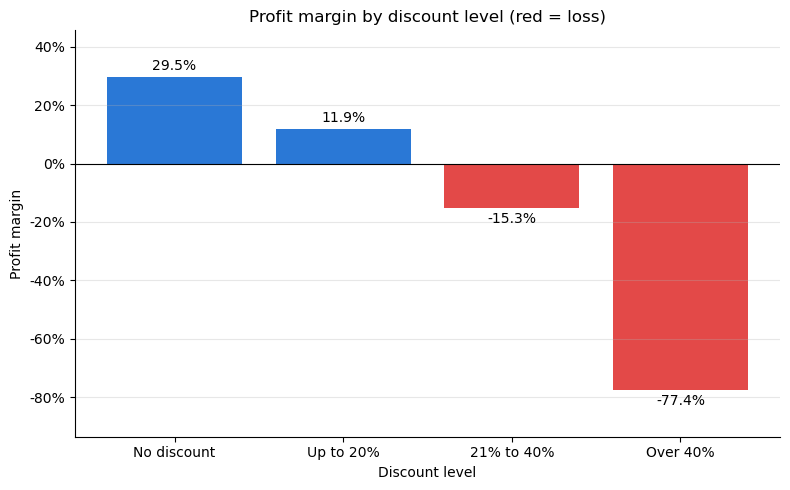

In [27]:
colors = ["#e34948" if value < 0 else "#2a78d6" for value in discount_summary["Margin %"]]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(discount_summary.index.astype(str), discount_summary["Margin %"], color=colors)

ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.margins(y=0.15)

ax.set_title("Profit margin by discount level (red = loss)")
ax.set_xlabel("Discount level")
ax.set_ylabel("Profit margin")
ax.yaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/discount_margin.png", dpi=300)
plt.show()

In [28]:
state_discount = df.groupby("State")["Discount"].mean() * 100
print(state_discount.loc[["Texas", "Pennsylvania", "Florida", "Illinois", "Ohio", "California", "New York"]].round(1))

print()

product_discount = df.groupby("Sub-Category")["Discount"].mean() * 100
print(product_discount.loc[["Tables", "Bookcases", "Supplies", "Copiers", "Paper"]].round(1))

State
Texas           37.0
Pennsylvania    32.9
Florida         29.9
Illinois        39.0
Ohio            32.5
California       7.3
New York         5.5
Name: Discount, dtype: float64

Sub-Category
Tables       26.1
Bookcases    21.1
Supplies      7.7
Copiers      16.2
Paper         7.5
Name: Discount, dtype: float64


In [29]:
#Why we do this: the PDF requires a README with an executive summary and recommendations. A manager won’t read your code, so this is where your numbers become decisions.
print(yearly_sales.round(0), "\n")
print(seasonal_sales.round(0), "\n")
print(category_summary, "\n")
print(subcategory_summary.head(3), "\n")
print(region_summary, "\n")
print("States losing money:", len(losing_states))

Year
2014    483966.0
2015    470533.0
2016    609206.0
2017    733215.0
Name: Sales, dtype: float64 

Order Date
1     23731.0
2     14938.0
3     51251.0
4     34370.0
5     38757.0
6     38180.0
7     36810.0
8     39761.0
9     76912.0
10    50081.0
11    88115.0
12    81323.0
Name: Sales, dtype: float64 

                   Revenue     Profit  Units  Margin %
Category                                              
Technology       836154.03  145454.95   6939     17.40
Furniture        741718.42   18463.33   8026      2.49
Office Supplies  719047.03  122490.80  22906     17.04 

                Revenue    Profit  Units  Margin %
Sub-Category                                      
Copiers       149528.03  55617.82    234     37.20
Phones        330007.05  44515.73   3289     13.49
Accessories   167380.32  41936.64   2976     25.05 

           Revenue     Profit  Orders  Margin %
Region                                         
West     725457.82  108418.45    1611     14.94
East     6